# Laboratorio di Analisi Numerica
## Lezione 10

Cecilia Pagliantini <cecilia.pagliantini@unipi.it>  
Leonardo Robol <leonardo.robol@unipi.it>  
2-3 dicembre 2026

*Aggiornamento da completare*

> **Quantità di esercizi:** in questa dispensa ci sono *più esercizi* di quanti uno studente medio riesca a farne durante una lezione di laboratorio, specialmente tenendo conto anche degli esercizi facoltativi. Questo perché è pensata per “tenere impegnati” per tutta la lezione anche quegli studenti che già hanno un solido background di programmazione.
>
> Quindi fate gli esercizi che riuscite, partendo da quelli *non* segnati come facoltativi, e non preoccupatevi se non li finite tutti!

Questa lezione di laboratorio è divisa in due parti: la prima verte sull'integrazione numerica, la seconda sulla risoluzione numerica di equazioni differenziali ordinarie. Si provino a completare almeno i primi esercizi di entrambe le parti.

Useremo `LinearAlgebra`, incluso nella libreria standard di Julia, e i pacchetti `Plots`, `Polynomials` e `NLsolve`. Se necessario, installate i pacchetti mancanti eseguendo una sola volta `using Pkg; Pkg.add(["Plots", "Polynomials", "NLsolve"])`.

Eseguite le celle dall'alto verso il basso e completate gli esercizi negli spazi predisposti. Le chiamate alle funzioni da scrivere sono commentate: togliete `#` dopo averle definite.

In [ ]:
using LinearAlgebra
using Plots
import Polynomials

## 1. Risoluzione numerica di equazioni differenziali ordinarie

Consideriamo il problema di Cauchy

$$\begin{cases}
y'(t)=f(t,y(t)),\\
y(t_0)=\eta.
\end{cases}$$

Determinare una soluzione analitica è generalmente difficile e spesso impossibile in termini di funzioni elementari, anche per equazioni apparentemente semplici come $y'=t^2+y^2$. Cerchiamo quindi una soluzione approssimata con un metodo numerico.

Studieremo il metodo di **Eulero esplicito** e quello di **Eulero implicito**, per problemi con soluzione scalare reale.

### 1.1. Il metodo di Eulero esplicito

Discretizziamo $[a,b]$ con i nodi equidistanti $t_n=a+nh$, per $n=0,\ldots,N$, con $h=(b-a)/N$. Il metodo di Eulero esplicito è

$$y_0=\eta,\qquad y_{n+1}=y_n+h f(t_n,y_n),\qquad n=0,\ldots,N-1.$$

### Esercizio 1

Scrivete una funzione `expliciteuler(f, y0, a, b, h)` che riceve la dinamica `f(t, y)`, la condizione iniziale `y0`, gli estremi `a`, `b` e il passo richiesto `h > 0`. Restituite **nell'ordine** `y, t`: il vettore delle approssimazioni e il vettore dei nodi.

Per includere sempre entrambi gli estremi, assumete `a < b`, scegliete `N = ceil(Int, (b-a)/h)` e costruite `t = collect(range(a, b; length=N+1))`. Usate nell'iterazione il passo effettivo `h_eff = (b-a)/N`, che è al più quello richiesto. Negli esperimenti seguenti i passi sono scelti in modo da suddividere esattamente l'intervallo.

**Julia:** il valore matematico $y_0$ va memorizzato in `y[1]`, e $t_0$ in `t[1]`. Una funzione può restituire due vettori con `return y, t`; la chiamata si scrive `y, t = expliciteuler(...)`.

In [ ]:
# Scrivete qui la funzione expliciteuler(f, y0, a, b, h)

Testiamo il codice sul problema

$$\begin{cases}
y'=-\dfrac{2y+t^2y^2}{t},\\
y(1)=1,
\end{cases}\qquad t\in[1,2],$$

la cui soluzione esatta è

$$y(t)=\frac{1}{t^2(\log t+1)}.$$

Disegniamo la soluzione approssimata e quella esatta, poi l'errore assoluto. Il primo errore è zero perché la condizione iniziale è assegnata esattamente: escludiamolo dal grafico in scala logaritmica.

In [ ]:
fode(t, y) = -(2*y + t^2*y^2) / t
ytrue(t) = 1 / (t^2 * (log(t) + 1))
a = 1.0
b = 2.0
h = 1e-2
y0 = 1.0
# y, t = expliciteuler(fode, y0, a, b, h)
# psol = plot(t, y; label="Soluzione approssimata", linestyle=:dash,
#             linewidth=2, xlabel="t")
# plot!(psol, t, ytrue.(t); label="Soluzione esatta", linewidth=2)
# errore = abs.(y - ytrue.(t))
# perr = plot(t[2:end], errore[2:end]; yscale=:log10, label=false,
#             xlabel="t", ylabel="Errore assoluto", linewidth=2)
# plot(psol, perr; layout=(1, 2), size=(1000, 350))

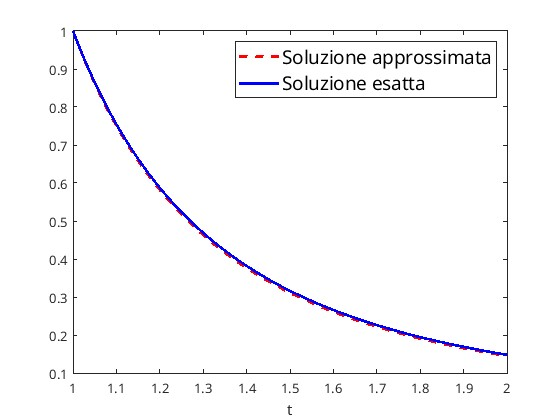

Soluzione approssimata con Eulero esplicito e soluzione esatta (dispensa originale).

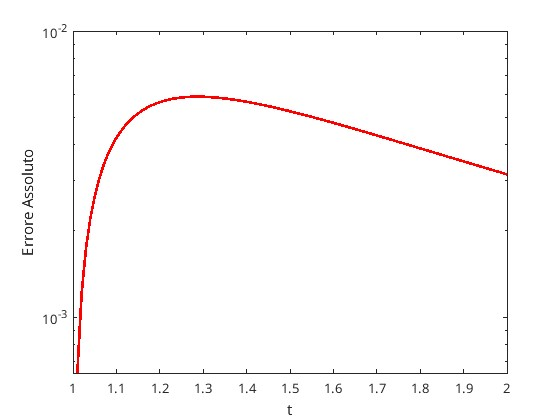

Errore assoluto del metodo di Eulero esplicito (dispensa originale).

### 1.2. Convergenza al diminuire del passo

Studiamo l'errore relativo in norma euclidea sui nodi,

$$E(h)=\frac{\lVert y_h-y_{\mathrm{esatta}}\rVert_2}{\lVert y_{\mathrm{esatta}}\rVert_2}.$$

Se $E(h)\approx C h^p$, possiamo stimare l'ordine del metodo con

$$p_i\approx\frac{\log(E(h_{i+1})/E(h_i))}{\log(h_{i+1}/h_i)}.$$

Usiamo passi successivamente dimezzati. Quale ordine vi aspettate per Eulero esplicito? Confrontate gli errori con una retta di pendenza $1$ in scala logaritmica.

In [ ]:
passi = 0.1 ./ (2.0 .^ (0:8))
# err = zeros(length(passi))
# for i in eachindex(passi)
#     yi, ti = expliciteuler(fode, 1.0, 1.0, 2.0, passi[i])
#     yt = ytrue.(ti)
#     err[i] = norm(yi - yt) / norm(yt)
# end
# pconv = plot(passi, err; xscale=:log10, yscale=:log10, marker=:circle,
#              xlabel="h", ylabel="Errore relativo", label="Eulero esplicito")
# plot!(pconv, passi, err[1] .* passi ./ passi[1]; label="Riferimento O(h)", linestyle=:dash)
# display(pconv)
# ordini = log.(err[2:end] ./ err[1:end-1]) ./ log.(passi[2:end] ./ passi[1:end-1])
# @show ordini

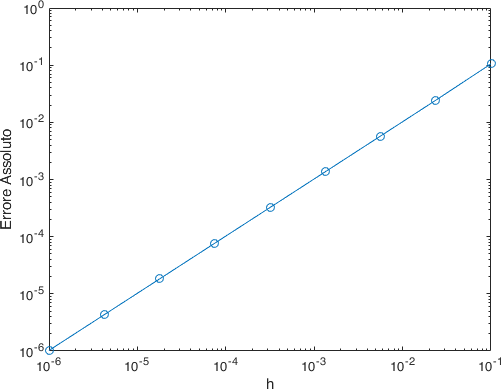

Errore del metodo di Eulero esplicito al variare del passo (dispensa originale).

La dispensa introduce anche l'ordine $r$ di una **successione** $x_n\to x$, definito dalla relazione asintotica

$$\frac{|x_{n+1}-x|}{|x_n-x|^r}\longrightarrow c>0,$$

con $c<1$ nel caso di convergenza lineare ($r=1$). Ponendo $e_n=|x_n-x|$, una stima basata su tre errori consecutivi è

$$r_n\approx\frac{\log(e_{n+1}/e_n)}{\log(e_n/e_{n-1})}.$$

Questa stima descrive la successione, mentre $p$ descrive la dipendenza dell'errore dal passo. Con passi dimezzati ed $E(h)\approx Ch^p$, la successione degli errori è geometrica e la formula per $r$ tende a $1$ per qualunque $p>0$. Per misurare l'ordine del metodo usate quindi la formula con i rapporti dei passi.

In [ ]:
function convergenza(xn, xtrue)
    e = abs.(xn .- xtrue)
    r = fill(NaN, max(length(e) - 2, 0))
    for n = 2:length(e)-1
        if all(isfinite, e[n-1:n+1]) && all(e[n-1:n+1] .> 0)
            denominatore = log(e[n] / e[n-1])
            if denominatore != 0
                r[n-1] = log(e[n+1] / e[n]) / denominatore
            end
        end
    end
    return r
end

# Dopo aver calcolato err:
# convergenza(err, 0.0)

### Esercizio 2

Ripetete lo studio numerico per

$$\begin{cases}y'(t)=-y(t),\\y(0)=1,\end{cases}\qquad t\in[0,30],$$

la cui soluzione esatta è $y(t)=e^{-t}$. Usate $h\in\{0.1,0.5,1,1.5,2\}$ e disegnate la soluzione al variare del tempo per ogni passo. Confrontate anche gli errori rispetto alla soluzione esatta.

Cosa osservate? Riuscite a spiegare teoricamente il comportamento ottenuto? Ricavate il fattore che lega $y_{n+1}$ a $y_n$ e discutete anche il caso limite $h=2$.

In [ ]:
fstab(t, y) = -y
ystab(t) = exp(-t)
passi_stabilita = [0.1, 0.5, 1.0, 1.5, 2.0]
# Inserite qui gli esperimenti, i grafici e il confronto degli errori

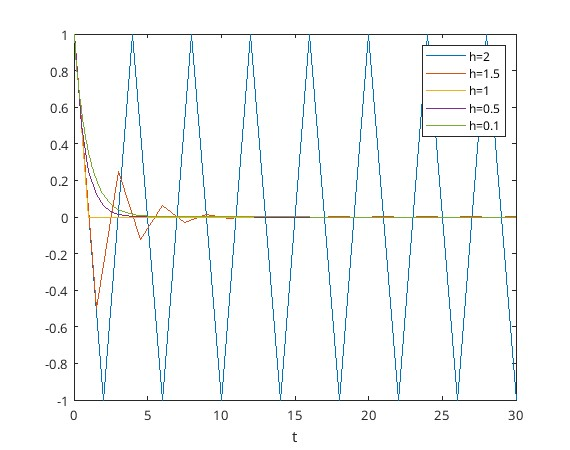

Eulero esplicito per il problema y′ = −y con diversi passi temporali (dispensa originale).

### 1.3. Il metodo di Eulero implicito

Un passo piccolo richiede molti nodi e aumenta il costo del calcolo. I metodi impliciti possono ridurre le restrizioni sul passo dovute alla stabilità; l'accuratezza va comunque verificata diminuendo $h$.

Il metodo di Eulero implicito è definito da

$$y_0=\eta,\qquad y_{n+1}=y_n+h f(t_{n+1},y_{n+1}),\qquad n=0,\ldots,N-1.$$

A ogni passo dobbiamo quindi risolvere, rispetto all'incognita $z=y_{n+1}$, l'equazione generalmente non lineare

$$G(z)=z-y_n-h f(t_{n+1},z)=0.$$

Per sostituire `fsolve` di MATLAB usiamo `NLsolve.nlsolve`. Il risolutore lavora con vettori: per una sola equazione rappresentiamo l'incognita con un vettore di lunghezza 1. Il campo `zero` contiene la soluzione; controllate la convergenza prima di usarla.

L'esempio seguente risolve un'equazione scalare. Per Eulero implicito dovrete cambiare il residuo a ogni passo e usare come stima iniziale l'approssimazione del passo precedente.

Riferimento: [NLsolve.jl: residui, stima iniziale e verifica della convergenza](https://github.com/JuliaNLSolvers/NLsolve.jl).

In [ ]:
import NLsolve

# Esempio: risolviamo z² - 2 = 0 partendo da z = 1.
risultato = NLsolve.nlsolve(z -> [z[1]^2 - 2], [1.0]; ftol=1e-12)
NLsolve.converged(risultato) || error("Il risolutore non è convergente")
@show risultato.zero[1];

### Esercizio 3

Scrivete una funzione `impliciteuler(f, y0, a, b, h)` che implementa Eulero implicito e restituisce `y, t`. Usate la stessa costruzione dei nodi e lo stesso passo effettivo dell'esercizio 7.

Risolvete l'equazione a ogni passo con `NLsolve.nlsolve`, usando il valore precedente come stima iniziale. Controllate `NLsolve.converged(risultato)` e segnalate un errore se il risolutore non converge. Scegliete una tolleranza sul residuo abbastanza piccola da non nascondere l'errore di discretizzazione, per esempio `ftol=1e-12`.

In [ ]:
# Scrivete qui la funzione impliciteuler(f, y0, a, b, h)

Verificate l'implementazione sul problema non lineare già usato per Eulero esplicito, con condizione iniziale `y0 = 1.0`, intervallo `[1, 2]` e passo `h = 1e-2`. Disegnate la soluzione e l'errore assoluto. Ripetete poi lo studio dell'ordine al diminuire del passo della sezione 2.2, sostituendo `expliciteuler` con `impliciteuler`.

In [ ]:
# yimp, timp = impliciteuler(fode, 1.0, 1.0, 2.0, 1e-2)
# psol_imp = plot(timp, yimp; label="Eulero implicito", linestyle=:dash,
#                 xlabel="t", linewidth=2)
# plot!(psol_imp, timp, ytrue.(timp); label="Soluzione esatta", linewidth=2)
# errore_imp = abs.(yimp - ytrue.(timp))
# perr_imp = plot(timp[2:end], errore_imp[2:end]; yscale=:log10,
#                 xlabel="t", ylabel="Errore assoluto", label=false)
# plot(psol_imp, perr_imp; layout=(1, 2), size=(1000, 350))

Confrontiamo infine i due metodi sul problema $y'=-y$, $y(0)=1$, per $t\in[0,30]$, con $h=2$.

Disegnate entrambe le approssimazioni e la soluzione esatta. Ricavate il fattore di amplificazione di Eulero implicito e confrontatelo con quello del metodo esplicito. Che differenza osservate nella stabilità? Un risultato stabile è necessariamente accurato?

In [ ]:
# yi, ti = impliciteuler(fstab, 1.0, 0.0, 30.0, 2.0)
# ye, te = expliciteuler(fstab, 1.0, 0.0, 30.0, 2.0)
# tfitto = range(0, 30; length=1001)
# pi_stab = plot(ti, yi; label="Soluzione approssimata", linestyle=:dash,
#                marker=:circle, title="Eulero implicito", xlabel="t")
# plot!(pi_stab, tfitto, ystab.(tfitto); label="Soluzione esatta")
# pe_stab = plot(te, ye; label="Soluzione approssimata", linestyle=:dash,
#                marker=:circle, title="Eulero esplicito", xlabel="t")
# plot!(pe_stab, tfitto, ystab.(tfitto); label="Soluzione esatta")
# plot(pi_stab, pe_stab; layout=(1, 2), size=(1000, 350))

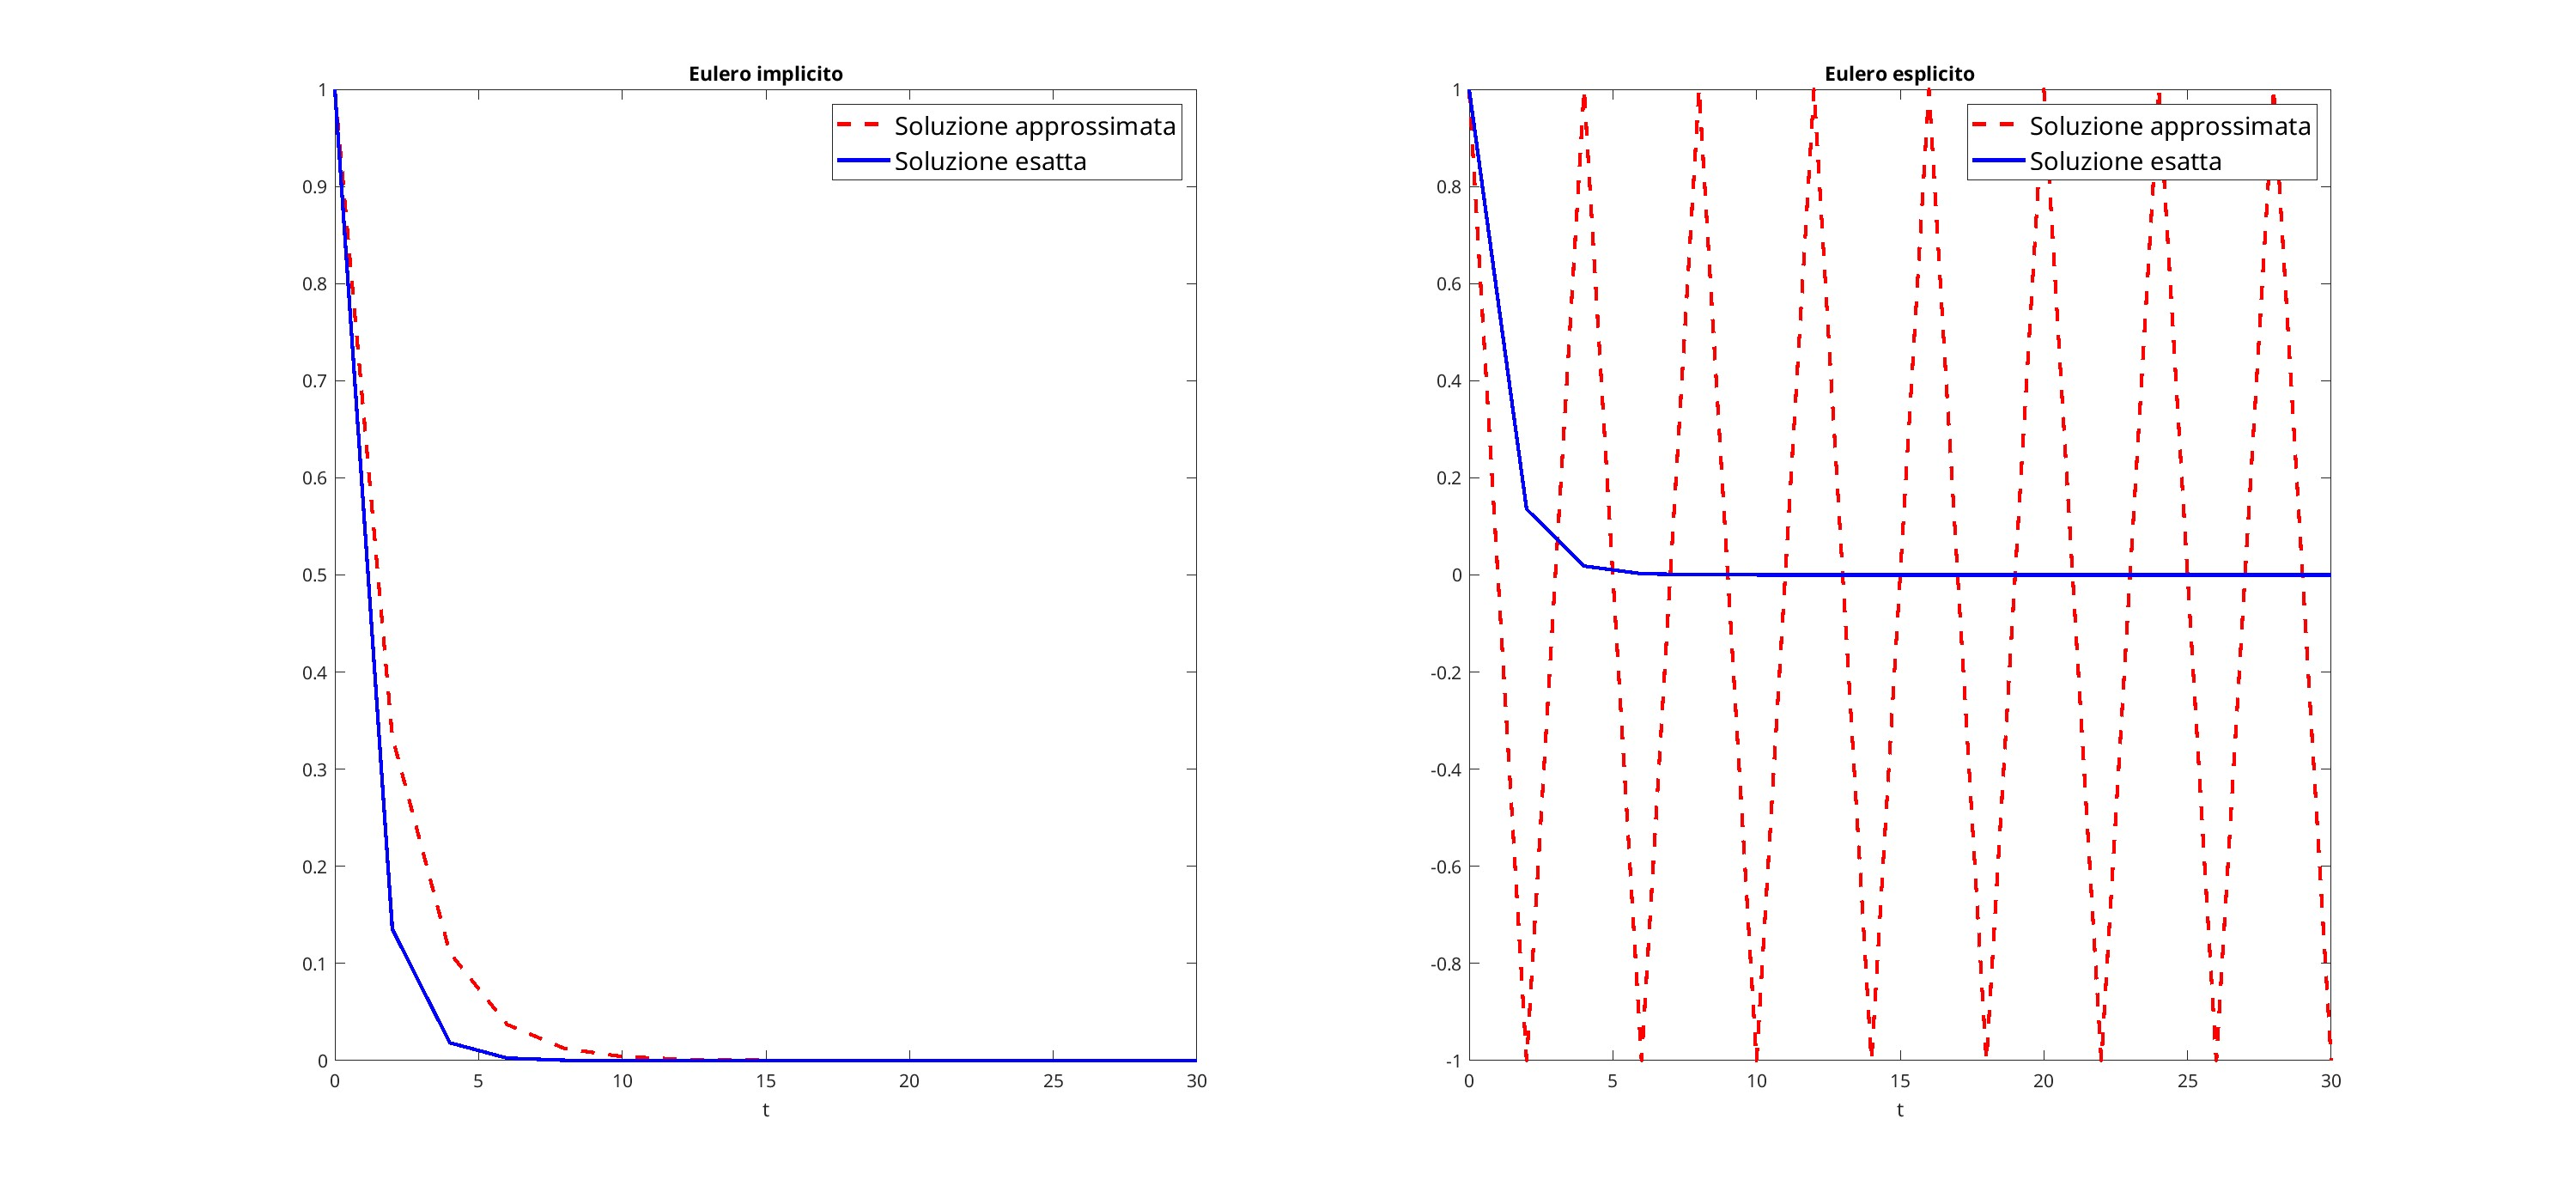

Confronto di stabilità tra Eulero implicito ed esplicito.